# Muriwai seasonal effect (results 1.4.1)

**Table:** Muriwai edge accuracy by season, summer (Oct–Mar) vs winter (Apr–Sep), for every scenario on Sentinel-2 and Landsat 8: MedAE / RMSE (median distance) in m, and the number of images per season. Saved as CSV and as a LaTeX table (needs `\usepackage{booktabs, multirow}`).

**Figure:** **(a)**, **(b)** VedgeSat's classification of one winter image (Landsat 8, 16 June 2017; NZCCD line 15 July 2017) with the extracted edge, for the default and the NZ classifier with Weighted Peaks, side by side, each with its name, threshold and errors in the lower-left corner; **(d)** under them, the NDVI densities of the vegetation and non-vegetation pixels of image (a) (above) and image (b) (mirrored below), with each threshold and transition zone, computed from the NDVI and CLASS GeoTIFFs the runs saved, inside the reference-line buffer as VedgeSat does; **(c)** to the right, the full height, split violins of the transect distances for the scenarios in `SEASON_SCENARIOS`: summer upper half, winter lower half, with the Sentinel-2 (red) and Landsat 8 (blue) distributions overlaid semi-transparently, medians as lines and listed on the right of each half, and the ±10 m and ±15 m pixel sizes shaded as in Muir et al. (2024).

Reads only saved outputs: `errors_all.csv` from the batch comparison, the detection figures the runs saved (`Data/<run>/img_files/detection/<date>_<sat>.jpg`, for the classification panels), and the runs' `img_files/*_NDVI.tif`, `*_CLASS.tif` and `_settings.pkl` (for (d)). Uses only images every scenario has. Everything is written to `Data/Extra_analyses/Muriwai_seasonal` (overwritten each run).

Run the settings cell, the functions cell, then the table and figure cells.

In [21]:
# ---------------- Settings ----------------
import os
DATA = os.path.join(os.getcwd(), 'Data')                        # run from the COASTGUARD-master folder
ERRORS_CSV = os.path.join(DATA, 'NZCCD_comparison_batch', 'errors_all.csv')
OUT_DIR = os.path.join(DATA, 'Extra_analyses', 'Muriwai_seasonal')   # table and figure; overwritten on every run
TAG, SITE = 'BatchS', 'Muriwai'

# Seasons by image month
SEASONS = {'Summer': [10, 11, 12, 1, 2, 3],      # Oct-Mar
           'Winter': [4, 5, 6, 7, 8, 9]}         # Apr-Sep

# Scenarios in the table (top to bottom); delete one to leave it out
SCENARIOS = ['default_WP', 'default_local', 'NZ_WP', 'NZ_local', 'NZsparse_WP', 'NZsparse_local']

# Example image: VedgeSat's classification (a, b) of one winter image and its NDVI densities (d), bad and good
EXAMPLE = dict(nzccd='2017-07-15', date='2017-06-16', sat='L8')
EXAMPLE_RUNS = [('default_WP', 'VedgeSat classifier,\nWeighted Peaks'),      # (a) bad
                ('NZ_WP', 'NZ classifier,\nWeighted Peaks')]                # (b) good
# Panel (d), the examples' NDVI densities, is computed from the NDVI and CLASS GeoTIFFs each run saved in
# Data/<run>/img_files, inside the run's reference-line buffer (read from its _settings.pkl; if that fails, from these)
REF_LINE = os.path.join(DATA, 'referenceLines', 'Muriwai_refLine.shp')
REF_BUFFER = 200         # m, max_dist_ref of the runs
HIST_XLIM = (-0.6, 0.8)  # NDVI range of (d); None = fitted to the pixels
HIST_HEIGHT = 1.9        # inches

# Panel (c): split violins of the transect distances, summer (upper half) vs winter (lower half); in each half the
# Sentinel-2 and Landsat 8 distributions overlap, semi-transparent, one colour per satellite
SEASON_SCENARIOS = ['default_WP', 'default_local', 'NZ_WP', 'NZ_local']   # top to bottom
SEASON_XLIM = 150        # m either side of NZCCD
SAT_COLOUR = {'S2': '#cb181d', 'L8': '#2171b5'}    # red, blue
SAT_ALPHA = 0.5
SAT_OUTLINE = {'S2': 0, 'L8': 0.6}                # outline width of each satellite's shape (0 = none)
PIXEL = {'S2': 10, 'L8': 15}                       # m, pixel sizes shaded as in Muir et al. (2024) (explain in the caption)

WITHIN = 10          # m, accuracy target ('% within' in the table)
FIG_WIDTH = 7.5      # inches; scale it to the text width when inserting (e.g. width=\textwidth)
CLASS_WIDTH = 1.85   # inches, width of each classification panel (side by side; height follows; (c) fills the rest of the width)
INFO_FONTSIZE = 6.3  # name and errors written in the corner of each classification
DPI = 300


In [25]:
# ---------------- Functions (run once; nothing to edit here) ----------------
import glob
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib import cbook, mlab, patheffects
from matplotlib.patches import Patch
from PIL import Image as PILImage
from IPython.display import display

SCEN_RUN = {'default_WP': 'Default (WP)', 'default_local': 'Default (local)', 'NZ_WP': 'NZ (WP)',
            'NZ_local': 'NZ (local)', 'NZsparse_WP': 'NZsparse (WP)', 'NZsparse_local': 'NZsparse (local)'}  # as in errors_all.csv
SCEN_SHORT = {'default_WP': 'VedgeSat WP', 'default_local': 'VedgeSat local', 'NZ_WP': 'NZ WP',
              'NZ_local': 'NZ local', 'NZsparse_WP': 'NZsparse WP', 'NZsparse_local': 'NZsparse local'}
SCEN_TABLE = {'default_WP': 'VedgeSat, Weighted Peaks', 'default_local': 'VedgeSat, local threshold',
              'NZ_WP': 'NZ, Weighted Peaks', 'NZ_local': 'NZ, local threshold',
              'NZsparse_WP': 'NZsparse, Weighted Peaks', 'NZsparse_local': 'NZsparse, local threshold'}
SCEN_COLOUR = {'default_WP': '#1a0b2e', 'default_local': '#1b068d',     # same colours as the site figures
               'NZ_WP': '#1560bd', 'NZ_local': '#8f99fb',
               'NZsparse_WP': '#cc5500', 'NZsparse_local': '#fca636'}
SAT_NAME = {'S2': 'Sentinel-2', 'L8': 'Landsat 8'}
ETA = r'$\eta_{dist}$'
signed = lambda v: f'{v:+.1f}'.replace('-', '−')
LIGHT = 0.55         # summer half = scenario colour mixed this much with white


def tint(colour, f=LIGHT):
    c = np.array(mpl.colors.to_rgb(colour))
    return tuple(c + (1 - c) * f)


def panel_letter(ax, letter):
    ax.text(0.04, 0.975, f'({letter})', transform=ax.transAxes, ha='left', va='top', fontsize=9, zorder=12,
            bbox=dict(fc='white', ec='black', lw=0.6, boxstyle='square,pad=0.25'))


def load_errors():
    E = pd.read_csv(ERRORS_CSV)
    E = E[(E.site == SITE) & E.run.isin([SCEN_RUN[k] for k in SCENARIOS])].copy()
    E['date'] = E['date'].astype(str).str[:10]
    E['nzccd_date'] = E['nzccd_date'].astype(str).str[:10]
    E['img'] = E.nzccd_date + '|' + E.date
    keep = []
    for sat, g in E.groupby('satname'):                  # only images every scenario has
        shared = set.intersection(*[set(gg.img) for _, gg in g.groupby('run')])
        dropped = sorted(set(g.img) - shared)
        if dropped:
            print(f'{SITE} {sat}: images not in every scenario, left out: {dropped}')
        keep.append(g[g.img.isin(shared)])
    E = pd.concat(keep)
    month = pd.to_datetime(E.date).dt.month
    E['season'] = None
    for s, months in SEASONS.items():
        E.loc[month.isin(months), 'season'] = s
    return E


def season_table(E):
    rows = []
    for sat in ['S2', 'L8']:
        for k in SCENARIOS:
            for s in SEASONS:
                g = E[(E.satname == sat) & (E.run == SCEN_RUN[k]) & (E.season == s)]
                e = g.error_m.values
                if not len(e):
                    continue
                rows.append({'satellite': sat, 'scenario': k, 'season': s, 'images': g.img.nunique(),
                             'transects': len(e), 'median_m': np.median(e), 'MedAE_m': np.median(np.abs(e)),
                             'RMSE_m': np.sqrt(np.mean(e ** 2)), f'within_{WITHIN}m_pct': 100 * np.mean(np.abs(e) <= WITHIN)})
    return pd.DataFrame(rows)


def write_latex(T, path):
    """booktabs table: satellite, scenario, then MedAE / RMSE (median) for each season."""
    seasons = list(SEASONS)
    n = {(r.satellite, r.season): r.images for r in T.itertuples()}
    head = ' & '.join([f'{s} (m)' for s in seasons])
    lines = [r'\begin{tabular}{ll' + 'c' * len(seasons) + '}', r'\toprule',
             r'Satellite & Scenario & ' + head + r' \\', r'\midrule']
    for i, sat in enumerate(['S2', 'L8']):
        sub = T[T.satellite == sat]
        if sub.empty:
            continue
        if i and len(lines) > 4:
            lines.append(r'\midrule')
        imgs = ', '.join(f'{n.get((sat, s), 0)} {s.lower()}' for s in seasons)
        for j, k in enumerate(SCENARIOS):
            cells = []
            for s in seasons:
                r = sub[(sub.scenario == k) & (sub.season == s)]
                cells.append('--' if r.empty else
                             f'{r.MedAE_m.iloc[0]:.1f} / {r.RMSE_m.iloc[0]:.1f} ({r.median_m.iloc[0]:+.1f})'.replace('-', '$-$'))
            first = (rf'\multirow{{{len(SCENARIOS)}}}{{*}}{{\shortstack[l]{{{SAT_NAME[sat]}\\({imgs})}}}}' if j == 0 else '')
            lines.append(f'{first} & {SCEN_TABLE[k]} & ' + ' & '.join(cells) + r' \\')
    lines += [r'\bottomrule', r'\end{tabular}']
    open(path, 'w', encoding='utf-8').write('\n'.join(lines) + '\n')


# ---------- VedgeSat detection figure: cut into its panels ----------
def _runs(mask):
    out, start = [], None
    for i, v in enumerate(mask):
        if v and start is None:
            start = i
        elif not v and start is not None:
            out.append((start, i)); start = None
    if start is not None:
        out.append((start, len(mask)))
    return out


def detection_jpg(run_key):
    folder = os.path.join(DATA, f"{TAG}_{SITE}_{EXAMPLE['nzccd']}_{run_key}", 'img_files', 'detection')
    hits = sorted(glob.glob(os.path.join(folder, f"{EXAMPLE['date']}*{EXAMPLE['sat']}*.jpg")))
    if not hits:
        raise FileNotFoundError(f"No detection figure for {EXAMPLE['date']} {EXAMPLE['sat']} in {folder}. "
                                'It is saved when the run has save_figure=True; check the date and satellite.')
    return hits[0]


def cut_detection(path):
    """Panels of a VedgeSat detection figure (titles and the histogram's y label left out):
    rgb, class, ndvi (the three maps) and hist (the NDVI histogram with its x axis)."""
    a = np.asarray(PILImage.open(path).convert('RGB'))
    ink = a.min(axis=2) < 235                        # anything not white
    rows = _runs(ink.mean(1) > 0.3)                  # [maps, histogram box]
    if len(rows) < 2:
        raise ValueError(f'Could not find the maps and histogram in {path}')
    (m0, m1), (h0, h1) = rows[0], rows[1]
    cols = [c for c in _runs(ink[m0:m1].mean(0) > 0.5) if c[1] - c[0] > 50]
    if len(cols) != 3:
        raise ValueError(f'Expected 3 maps in {path}, found {len(cols)}')
    out = {k: a[m0:m1, c0:c1] for k, (c0, c1) in zip(['rgb', 'class', 'ndvi'], cols)}
    box = [c for c in _runs(ink[h0:h1].mean(0) > 0.5)]
    b0, b1 = box[0][0], box[-1][1]
    below = [r for r in _runs(ink[h1:h1 + 90].mean(1) > 0) if r[0] < 60]   # tick marks and their labels under the box
    t1 = h1 + (below[-1][1] if below else 0) + 4
    lab = _runs(ink[h1:t1].mean(0) > 0)
    c0 = min(b0, lab[0][0]) - 3 if lab else b0 - 3
    c1 = max(b1, lab[-1][1]) + 3 if lab else b1 + 3
    out['hist'] = a[h0 - 2:t1, c0:c1]
    return out


def example_threshold(run_key):
    """Threshold of the example image, from the run's veglines shapefile (None if not found)."""
    try:
        import geopandas as gpd
        f = [p for p in glob.glob(os.path.join(DATA, f"{TAG}_{SITE}_{EXAMPLE['nzccd']}_{run_key}", 'lines', '*.shp'))
             if 'vegline' in os.path.basename(p).lower() and 'water' not in os.path.basename(p).lower()]
        if f:
            g = gpd.read_file(sorted(f, key=len)[0])
            g = g[(g['dates'].astype(str).str[:10] == EXAMPLE['date']) & (g.satname == EXAMPLE['sat'])]
            col = next((c for c in g.columns if c.lower() in ('vthreshold', 'threshold', 'vthresh')), None)
            if col and len(g):
                return float(g[col].iloc[0])
    except Exception as e:
        print('Threshold not read from the veglines file:', repr(e))
    return None


def example_info(E, run_key):
    """Lines of text for the corner of an example: threshold and this image's errors."""
    info = []
    t = example_threshold(run_key)
    if t is not None:
        info.append(f'Threshold: {t:.2f}')
    e = E[(E.run == SCEN_RUN[run_key]) & (E.satname == EXAMPLE['sat']) & (E.date == EXAMPLE['date'])
          & (E.nzccd_date == EXAMPLE['nzccd'])].error_m.values
    if len(e):
        info += [f'{ETA} = {signed(np.median(e))} m', f'MedAE = {np.median(np.abs(e)):.1f} m',
                 f'RMSE = {np.sqrt(np.mean(e ** 2)):.1f} m']
    else:
        print(f'No errors for {run_key} on {EXAMPLE["date"]} {EXAMPLE["sat"]} in errors_all.csv')
    return info


# ---------- NDVI of the example image, from the GeoTIFFs the run saved (savetifs=True) ----------
def reference_line(run, crs):
    """The run's reference line and buffer distance (m): from its settings file, else REF_LINE / REF_BUFFER."""
    import pickle
    from shapely.geometry import LineString
    try:
        with open(os.path.join(DATA, run, run + '_settings.pkl'), 'rb') as fh:
            s = pickle.load(fh)
        ref = np.asarray(s['reference_shoreline'])
        return LineString(ref[:, :2]), float(s['max_dist_ref']), 'settings file'
    except Exception as e:
        import geopandas as gpd
        from shapely.ops import unary_union
        g = gpd.read_file(REF_LINE).to_crs(crs)
        return unary_union(list(g.geometry)), float(REF_BUFFER), f'{os.path.basename(REF_LINE)} ({e.__class__.__name__} reading settings)'


SAT_PREFIX = {'L8': ('LC08',), 'L9': ('LC09',), 'L5': ('LT05',), 'L7': ('LE07',)}   # Earth Engine image IDs


def find_tif(folder, kind):
    """The example image's GeoTIFF of one kind (NDVI, CLASS, ...). Files are named by Earth Engine image ID, e.g.
    LC08_074085_20170616_NDVI.tif (Landsat 8) or 20170628T222549_20170628T222543_T59HQV_NDVI.tif (Sentinel-2)."""
    d8 = EXAMPLE['date'].replace('-', '')
    hits = sorted(glob.glob(os.path.join(folder, f'*{d8}*_{kind}.tif')) +
                  glob.glob(os.path.join(folder, f"{EXAMPLE['date']}*_{kind}.tif")))
    pre = SAT_PREFIX.get(EXAMPLE['sat'])
    if pre:
        hits = [h for h in hits if os.path.basename(h).startswith(pre)]
    else:                                                       # Sentinel-2: not a Landsat ID
        hits = [h for h in hits if not os.path.basename(h).startswith(('LC0', 'LE0', 'LT0'))]
    if len(hits) > 1:
        print(f'{len(hits)} {kind} files for {EXAMPLE["date"]} {EXAMPLE["sat"]}; using {os.path.basename(hits[0])}')
    return hits[:1]


def example_pixels(run_key):
    """NDVI of the vegetation and non-vegetation pixels VedgeSat uses for the histogram and threshold: the classified
    pixels inside the reference-line buffer, dilated by 5 pixels as in VedgeSat (Image_Processing.ClipIndexVec).
    VedgeSat's random balancing of the two classes is left out: it does not change the shape of each density."""
    import rasterio
    from rasterio import features
    run = f"{TAG}_{SITE}_{EXAMPLE['nzccd']}_{run_key}"
    folder = os.path.join(DATA, run, 'img_files')
    nd, cl = find_tif(folder, 'NDVI'), find_tif(folder, 'CLASS')
    if not nd or not cl:
        raise FileNotFoundError(f"No NDVI / CLASS GeoTIFF for {EXAMPLE['date']} {EXAMPLE['sat']} in {folder} "
                                '(they are saved when extract_veglines runs with savetifs=True).')
    with rasterio.open(nd[0]) as src:
        ndvi, tr, crs, shape = src.read(1).astype(float), src.transform, src.crs, src.shape
    with rasterio.open(cl[0]) as src:
        cls = src.read(1)
    line, dist, source = reference_line(run, crs)
    px = abs(tr.a)
    zone = features.rasterize([(line.buffer(dist + 5 * px), 1)], out_shape=shape, transform=tr, fill=0).astype(bool)
    ok = zone & np.isfinite(ndvi)
    veg, non = ndvi[ok & (cls == 1)], ndvi[ok & (cls == 2)]
    print(f'{run_key}: {os.path.basename(nd[0])}; buffer {dist:.0f} m + 5 px from the {source}; '
          f'{len(veg)} vegetation and {len(non)} non-vegetation pixels')
    return veg, non


def mirror_hist_panel(ax, pix, thresholds, labels, letter):
    """NDVI densities of the two examples on one axis: the first above, the second mirrored below, the NDVI values
    between them. Vegetation green, non-vegetation purple-grey (the classification colours); threshold dashed;
    transition zone orange (VedgeSat's: 0.5th to 10th percentile of the vegetation NDVI, Toolbox.TZValues).
    The names of the two halves sit in a margin on the right, the key along the top."""
    bins = np.arange(-1, 1.0001, 0.01)                         # VedgeSat's 0.01 bins
    allv = np.concatenate([np.concatenate(p) for p in pix])
    lo, hi = HIST_XLIM or (np.floor(np.percentile(allv, 0.5) * 10) / 10 - 0.05,
                           np.ceil(np.percentile(allv, 99.5) * 10) / 10 + 0.05)
    pad = 0.06 * (hi - lo)                                     # gap at the right end of the NDVI axis
    x0, x1 = lo - 0.09 * (hi - lo), hi + pad                   # a little more on the left, clear of the border
    right = x1 + 0.37 * (x1 - x0)                              # label margin = 27% of the panel width
    dens = [[np.histogram(v, bins=bins, density=True)[0] for v in p] for p in pix]
    top = max(d.max() for dd in dens for d in dd)
    gap = 0.1 * top                                            # space for the NDVI numbers between the halves
    cols = {'veg': '#4daf4a', 'non': '#8c86b8', 'tz': '#ff9f1c'}
    for k, (p, dd, t, sgn) in enumerate(zip(pix, dens, thresholds, (1, -1))):
        base = sgn * gap
        if len(p[0]):                                          # transition zone
            z0, z1 = np.percentile(p[0], [0.5, 10])
            ax.fill_between([z0, z1], base, base + sgn * top * 1.05, color=cols['tz'], alpha=0.35, lw=0, zorder=1.5)
        for d, c, a in [(dd[1], cols['non'], 0.75), (dd[0], cols['veg'], 0.6)]:
            ax.stairs(base + sgn * d, bins, baseline=base, fill=True, color=c, alpha=a, lw=0, zorder=2)
        if t is not None:
            ax.plot([t, t], [base, base + sgn * top * 1.05], color='black', lw=1.1, ls=(0, (3, 2)), zorder=4)
            ax.text(t, base + sgn * top * 0.97, f'{t:.2f} ', fontsize=6.5, ha='right', va='center', zorder=5,
                    bbox=dict(fc='white', ec='none', alpha=0.8, pad=0.6))
        ax.plot([lo, hi], [base, base], color='#666666', lw=0.6, zorder=3)
        ax.text(x1 + 0.03 * (x1 - x0), base + sgn * top * 0.55, labels[k], fontsize=6.3, ha='left',
                va='center', linespacing=1.3, zorder=6)
    step = 0.1 if hi - lo <= 1.0 else 0.2
    ticks = np.arange(np.ceil(lo / step - 1e-9) * step, hi + 1e-9, step)      # on multiples of step, so 0 is one
    ticks = np.round(ticks, 2)
    for x in ticks:                                            # tick marks on both baselines, numbers between
        ax.plot([x, x], [gap, gap + 0.03 * top], color='#666666', lw=0.6, zorder=3)
        ax.plot([x, x], [-gap, -gap - 0.03 * top], color='#666666', lw=0.6, zorder=3)
        ax.text(x, 0, f'{x:.1f}'.replace('-', '\u2212'), fontsize=6.3, ha='center', va='center', zorder=3)
    ax.text(x1 + 0.03 * (x1 - x0), 0, 'NDVI', fontsize=6.3, ha='left', va='center', style='italic', color='#444')
    ax.axvline(x1, color='#dddddd', lw=0.6, zorder=1)          # edge of the label margin
    ax.set_xlim(x0, right)
    ax.set_ylim(-gap - top * 1.12, gap + top * 1.42)        # room along the top for the key
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(0.8)
    ax.text(0.012, 0.97, f'({letter})', transform=ax.transAxes, ha='left', va='top', fontsize=9, zorder=12,
            bbox=dict(fc='white', ec='black', lw=0.6, boxstyle='square,pad=0.25'))
    ax.legend([Patch(fc=cols['veg'], alpha=0.6), Patch(fc=cols['non'], alpha=0.75),
               plt.Line2D([], [], color='black', lw=1.1, ls=(0, (3, 2))), Patch(fc=cols['tz'], alpha=0.35)],
              ['Vegetation', 'Non-vegetation', 'Threshold', 'Transition zone'], loc='upper left',
              bbox_to_anchor=(0.075, 1.0), ncol=4, fontsize=6, frameon=False, handlelength=1.3, columnspacing=0.8,
              handletextpad=0.35, borderpad=0.35)


# ---------- split violins: summer above, winter below; S2 and L8 overlaid, semi-transparent ----------
MED_COLS = (0.69, 0.835, 0.99)         # right edges (axes fraction) of the season label and the S2 and L8 medians
def half_shape(e, xl, width=0.34):
    st = cbook.violin_stats(np.clip(e, -xl, xl), lambda X, c: mlab.GaussianKDE(X, 'scott').evaluate(c), points=400)[0]
    return st['coords'], width * st['vals'] / st['vals'].max()


def season_panel(ax, frame, E, letter):
    """ax = the plot (grey, no outline); frame = the bordered panel around it, whose white margin holds the letter
    and heading above and the axis and key below (as in the sparse-zone figure)."""
    xl = SEASON_XLIM
    s1, s2 = list(SEASONS)[:2]
    sats = [s for s in ['S2', 'L8'] if s in E.satname.values]
    ax.set_facecolor('#f2f2f2')
    for (sat, px), c in zip(sorted(PIXEL.items(), key=lambda t: -t[1]), ['#e2e2e2', '#cfcfcf']):
        ax.axvspan(-px, px, color=c, zorder=0, lw=0)                    # pixel sizes, as Muir et al.
    ax.axvline(0, color='#7a7a7a', lw=0.8, zorder=1)
    yax = ax.get_yaxis_transform()
    for i, k in enumerate(SEASON_SCENARIOS):
        y = i + 0.1
        meds = {}
        for season, side in [(s1, -1), (s2, +1)]:
            for sat in sats:
                e = E[(E.run == SCEN_RUN[k]) & (E.satname == sat) & (E.season == season)].error_m.values
                if not len(e):
                    continue
                meds[(sat, season)] = m = np.median(e)
                if len(e) < 2 or np.std(e) == 0:
                    continue
                xs, h = half_shape(e, xl)
                ax.fill_between(xs, y, y + side * h, facecolor=SAT_COLOUR[sat], alpha=SAT_ALPHA, edgecolor='none',
                                zorder=2)
                if SAT_OUTLINE.get(sat, 0):
                    ax.plot(xs, y + side * h, color=SAT_COLOUR[sat], lw=SAT_OUTLINE[sat], zorder=2.5)
                if -xl < m < xl:                                     # median
                    ax.plot([m, m], [y, y + side * np.interp(m, xs, h)], color=SAT_COLOUR[sat], lw=1.4, zorder=3,
                            solid_capstyle='butt')
        ax.plot([-xl, xl], [y, y], color='#555555', lw=0.5, zorder=3.5)           # the split
        ax.text(0.012, i - 0.42, SCEN_TABLE[k], transform=yax, fontsize=6.8, ha='left', va='top', zorder=5)
        # right side: season, then each satellite's median, summer above the split and winter below it
        for season, dy, va in [(s1, -0.035, 'bottom'), (s2, 0.035, 'top')]:
            ax.text(MED_COLS[0], y + dy, season.lower(), transform=yax, fontsize=5.8, color='#555555', ha='right',
                    va=va, zorder=5, style='italic')
            for sat, x in zip(sats, MED_COLS[1:]):
                v = meds.get((sat, season))
                ax.text(x, y + dy, f"{sat} {signed(v) if v is not None else '–'}", transform=yax, fontsize=6.3,
                        color=SAT_COLOUR[sat], ha='right', va=va, zorder=5, fontweight='bold')
    ax.set_yticks([])
    ax.set_ylim(len(SEASON_SCENARIOS) - 0.4, -0.5)
    ax.set_xlim(-xl, xl)
    step = 50 if xl > 60 else 20
    ticks = np.arange(-(xl // step) * step, xl + 1e-9, step)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'{t:g}'.replace('-', '\u2212') for t in ticks], fontsize=7)
    ax.tick_params(axis='x', direction='out', length=2.5, pad=1.5)
    labs = ax.get_xticklabels()                      # end labels kept inside the plot's width
    if len(labs) > 1 and abs(ticks[0]) >= xl:
        labs[0].set_ha('left'); labs[-1].set_ha('right')
    for sp in ax.spines.values():
        sp.set_visible(False)
    lab = ax.set_xlabel('Distance$_{satellite - NZCCD}$ (m)', fontsize=7.5, labelpad=2)
    for x, t, c, ha in [(0, 'land', '#b39b62', 'left'), (1, 'sea', '#2d6a9f', 'right')]:
        ax.annotate(t, xy=(x, 0.5), xycoords=('axes fraction', lab), color=c, fontsize=7.5, ha=ha, va='center')
    # heading and letter in the frame's top margin
    fh = frame.get_position().height * frame.figure.get_figheight()
    ty = 1 - 0.2 / fh
    frame.text(0.03, ty, f'({letter})', transform=frame.transAxes, ha='left', va='center', fontsize=10,
               bbox=dict(fc='white', ec='black', lw=0.6, boxstyle='square,pad=0.25'))
    n = E.groupby(['satname', 'season']).img.nunique()
    frame.text(0.15, ty + 0.05 / fh, 'Transect distances to NZCCD, summer vs winter', transform=frame.transAxes,
               fontsize=8, ha='left', va='center')
    frame.text(0.15, ty - 0.12 / fh, '; '.join(f"{s}: {n.get((s, s1), 0)} {s1.lower()}, "
                                              f"{n.get((s, s2), 0)} {s2.lower()} images" for s in sats),
               transform=frame.transAxes, fontsize=6, color='#444', ha='left', va='center')
    frame.text(0.97, 1 - 0.43 / fh, f'Median distance, {ETA} (m)', transform=frame.transAxes,
               fontsize=6, color='#444', ha='right', va='center')
    # key in the frame's bottom margin
    mon = lambda m: f"{pd.Timestamp(2000, m[0], 1):%b}–{pd.Timestamp(2000, m[-1], 1):%b}"
    hs = [Patch(fc=SAT_COLOUR[s], alpha=SAT_ALPHA, ec=SAT_COLOUR[s], lw=SAT_OUTLINE.get(s, 0)) for s in sats]
    ls = [SAT_NAME[s] for s in sats]
    frame.legend(hs, ls, loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=len(sats), fontsize=6.3, frameon=False,
                 handlelength=1.5, columnspacing=1.4, labelspacing=0.3, borderpad=0.2,
                 title=f'Upper half {s1.lower()} ({mon(SEASONS[s1])}), lower half {s2.lower()} ({mon(SEASONS[s2])})',
                 title_fontsize=6.3)


# ---------- the figure ----------
def seasonal_figure(E):
    """Left: (a), (b) the two examples' classifications side by side (name and errors in the lower-left corner), and
    under them (d) their NDVI densities, mirrored. Right: (c) split violins, summer vs winter, the full height."""
    W, g, gp = FIG_WIDTH, 0.14, 0.06
    cuts = [cut_detection(detection_jpg(k)) for k, _ in EXAMPLE_RUNS]
    n = len(cuts)
    cw = CLASS_WIDTH
    ch = cw * cuts[0]['class'].shape[0] / cuts[0]['class'].shape[1]
    lw = n * cw + (n - 1) * gp                                # left column width
    dx = lw + g                                               # (c) starts here
    dw = W - dx
    H = 0.02 + ch + gp + HIST_HEIGHT + 0.02
    fig = plt.figure(figsize=(W, H))
    box = lambda x, top, w, h: fig.add_axes([x / W, (H - top - h) / H, w / W, h / H])   # placed from the top
    d = pd.to_datetime(EXAMPLE['date'])
    for j, ((key, label), cut) in enumerate(zip(EXAMPLE_RUNS, cuts)):
        ax = box(j * (cw + gp), 0.02, cw, ch)
        ax.imshow(cut['class'], aspect='auto', interpolation='lanczos')
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_linewidth(0.8)
        panel_letter(ax, 'ab'[j])
        txt = ax.text(0.04, 0.02, '\n'.join(example_info(E, key)), transform=ax.transAxes, fontsize=INFO_FONTSIZE,
                      ha='left', va='bottom', linespacing=1.4)
        ax.annotate(f"{label}\n{SAT_NAME[EXAMPLE['sat']]},\n{d.day} {d:%B %Y}", xy=(0, 1), xycoords=txt,
                    xytext=(0, 2.5), textcoords='offset points', fontsize=INFO_FONTSIZE, fontweight='bold',
                    ha='left', va='bottom', linespacing=1.25)
    # (c): bordered panel, the full height
    frame = box(dx, 0.02, dw, H - 0.04)
    frame.set_xticks([]); frame.set_yticks([])
    for sp in frame.spines.values():
        sp.set_linewidth(0.8)
    pt, pb, side = 0.62, 0.74, 0.1                           # top: letter, heading; bottom: axis labels and key
    ax = box(dx + side, 0.02 + pt, dw - 2 * side, H - 0.04 - pt - pb)
    season_panel(ax, frame, E, 'c')
    # (d): NDVI densities of (a) above and (b) below, from the run's GeoTIFFs
    ax = box(0, 0.02 + ch + gp, lw, HIST_HEIGHT)
    pix = [example_pixels(k) for k, _ in EXAMPLE_RUNS]
    names = [f"Image ({'ab'[j]})\n" + lab for j, (k, lab) in enumerate(EXAMPLE_RUNS)]
    mirror_hist_panel(ax, pix, [example_threshold(k) for k, _ in EXAMPLE_RUNS], names, 'd')
    os.makedirs(OUT_DIR, exist_ok=True)
    png = os.path.join(OUT_DIR, f'{SITE}_seasonal_figure.png')
    fig.savefig(png, dpi=DPI, bbox_inches='tight')
    fig.savefig(png.replace('.png', '.pdf'), bbox_inches='tight')
    print('Saved', png, '(and .pdf)')
    display(fig)
    plt.close(fig)


## Table

In [26]:
# ---------------- Table: Muriwai, summer vs winter ----------------
E = load_errors()
T = season_table(E)
os.makedirs(OUT_DIR, exist_ok=True)
csv = os.path.join(OUT_DIR, f'{SITE}_seasonal_table.csv')
T.round(1).to_csv(csv, index=False)
write_latex(T, csv.replace('.csv', '.tex'))
print('Saved', csv, 'and', os.path.basename(csv.replace('.csv', '.tex')))

# as it will read in the dissertation: MedAE / RMSE (median distance), m
show = T.assign(cell=[f'{r.MedAE_m:.1f} / {r.RMSE_m:.1f} ({r.median_m:+.1f})' for r in T.itertuples()],
                Satellite=T.satellite.map(SAT_NAME), Scenario=T.scenario.map(SCEN_TABLE))
show = show.pivot_table(index=['Satellite', 'Scenario'], columns='season', values='cell', aggfunc='first', sort=False)
display(show)
print('Images per season:', T.groupby(['satellite', 'season']).images.first().to_dict())

Saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Extra_analyses/Muriwai_seasonal/Muriwai_seasonal_table.csv and Muriwai_seasonal_table.tex


season                                             Summer               Winter
Satellite  Scenario                                                           
Sentinel-2 VedgeSat, Weighted Peaks     6.0 / 12.2 (+4.6)  52.5 / 65.1 (-51.8)
           VedgeSat, local threshold  18.4 / 37.3 (-17.8)  22.4 / 39.8 (-22.3)
           NZ, Weighted Peaks           6.1 / 12.3 (+4.9)     4.4 / 6.9 (+1.0)
           NZ, local threshold          8.9 / 22.4 (-8.6)    6.0 / 12.8 (-5.7)
           NZsparse, Weighted Peaks     6.0 / 12.2 (+4.6)     4.4 / 6.9 (+1.0)
           NZsparse, local threshold     5.7 / 9.2 (+5.1)     4.5 / 7.6 (+4.0)
Landsat 8  VedgeSat, Weighted Peaks   26.9 / 43.1 (-23.3)  55.7 / 68.9 (-55.7)
           VedgeSat, local threshold  26.6 / 40.0 (-25.9)  38.2 / 53.2 (-37.8)
           NZ, Weighted Peaks         35.3 / 46.2 (+34.9)  23.0 / 29.0 (+23.0)
           NZ, local threshold          9.3 / 16.3 (+4.5)  11.4 / 13.1 (+10.2)
           NZsparse, Weighted Peaks   36.3 / 48.0 (+35.9)  23.0 / 29.0 (+23.0)
           NZsparse, local threshold  26.4 / 30.0 (+26.3)  21.8 / 25.3 (+21.8)

Images per season: {('L8', 'Summer'): 4, ('L8', 'Winter'): 4, ('S2', 'Summer'): 4, ('S2', 'Winter'): 2}


## Figure

default_WP: LC08_074085_20170616_NDVI.tif; buffer 200 m + 5 px from the settings file; 2504 vegetation and 9199 non-vegetation pixels
NZ_WP: LC08_074085_20170616_NDVI.tif; buffer 200 m + 5 px from the settings file; 5983 vegetation and 5720 non-vegetation pixels
Saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Extra_analyses/Muriwai_seasonal/Muriwai_seasonal_figure.png (and .pdf)


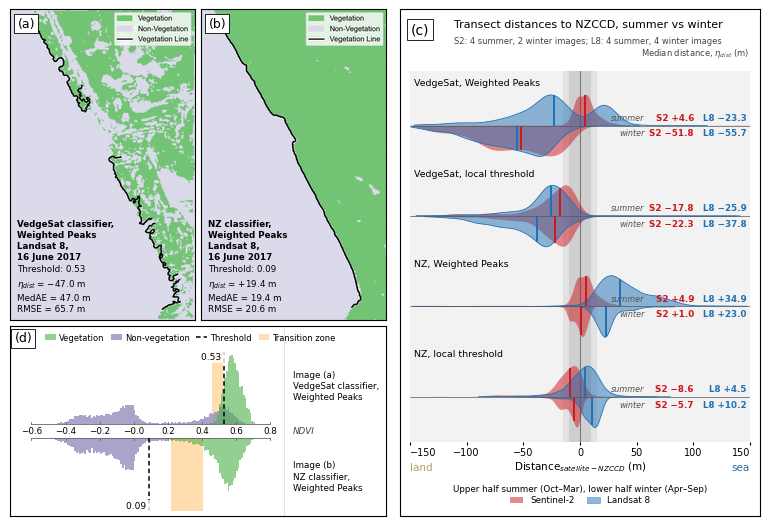

In [27]:
# ---------------- Figure: example image (a, b) and seasonal violins (c, d) ----------------
seasonal_figure(load_errors())

Saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Extra_analyses/Threshold/wp_threshold_sensitivity.png (and .pdf)


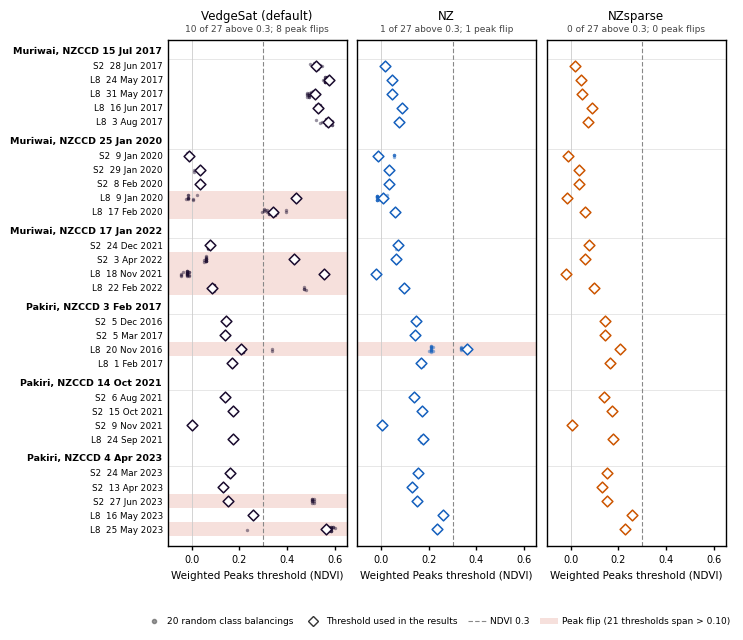

In [28]:
# =====================================================================================
# Weighted Peaks threshold sensitivity: strip plot of the 21 thresholds per image (results, threshold behaviour)
# =====================================================================================
# Reads Data/BatchS_wp_draws.csv (20 random class balancings per image) and Data/BatchS_wp_stability.csv
# (the threshold of the reported, seeded run). One row per image, one panel per classifier: small dots = the 20
# draws, large marker = the threshold VedgeSat used in the results. Rows where the 21 thresholds span more than
# 0.10 (a peak flip) are shaded. Saves PNG and PDF to Data/Extra_analyses/Threshold (overwritten each run).
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

DATA = os.path.join(os.getcwd(), 'Data')                     # run from the COASTGUARD-master folder
OUT_TH = os.path.join(DATA, 'Extra_analyses', 'Threshold')
CLASSIFIERS = ['default', 'NZ', 'NZsparse']
TITLE = {'default': 'VedgeSat (default)', 'NZ': 'NZ', 'NZsparse': 'NZsparse'}
COLOUR = {'default': '#1a0b2e', 'NZ': '#1560bd', 'NZsparse': '#cc5500'}   # Weighted Peaks colours of the site figures
XLIM = (-0.1, 0.65)            # NDVI
HIGH = 0.3                     # thresholds above this put the edge inside the vegetation (dashed line)
FLIP = 0.10                    # range of the 21 thresholds above which a row counts as a peak flip (shaded)
ROW_H = 0.16                   # inches per image row

S = pd.read_csv(os.path.join(DATA, 'BatchS_wp_stability.csv'))
Dr = pd.read_csv(os.path.join(DATA, 'BatchS_wp_draws.csv'))
S['date'] = S['date'].astype(str).str[:10]; Dr['date'] = Dr['date'].astype(str).str[:10]
S['nzccd'] = S['nzccd'].astype(str).str[:10]
lo = np.minimum(S['min'], S.used_threshold); hi = np.maximum(S['max'], S.used_threshold)
S['range21'] = (hi - lo).round(3)
S['run_key'] = S['run']

# row order: site, NZCCD line, satellite, date (same rows in every panel)
rows = (S[S.classifier == CLASSIFIERS[0]][['site', 'nzccd', 'sat', 'date']]
        .assign(sat_o=lambda d: d.sat.map({'S2': 0, 'L8': 1}))
        .sort_values(['site', 'nzccd', 'sat_o', 'date']).reset_index(drop=True))
groups = rows.groupby(['site', 'nzccd'], sort=False).size()
ypos, y, labels, heads = {}, 0, [], []
for (site, nz), n in groups.items():
    heads.append((y, f"{site}, NZCCD {pd.to_datetime(nz).day} {pd.to_datetime(nz):%b %Y}"))
    y += 1                                         # a row for the group heading
    for r in rows[(rows.site == site) & (rows.nzccd == nz)].itertuples():
        ypos[(site, nz, r.sat, r.date)] = y
        d = pd.to_datetime(r.date)
        labels.append((y, f"{r.sat}  {d.day} {d:%b %Y}"))
        y += 1
    y += 0.4                                       # gap between lines
n_rows = y

fig, axes = plt.subplots(1, len(CLASSIFIERS), figsize=(7.2, n_rows * ROW_H + 0.9), sharey=True,
                         gridspec_kw=dict(wspace=0.06))
rng = np.random.default_rng(0)
for ax, clf in zip(axes, CLASSIFIERS):
    s = S[S.classifier == clf]
    for r in s.itertuples():
        yy = ypos[(r.site, r.nzccd, r.sat, r.date)]
        if r.range21 > FLIP:
            ax.axhspan(yy - 0.5, yy + 0.5, color='#f6e0dc', zorder=0, lw=0)
        v = Dr[(Dr.run == r.run_key) & (Dr.date == r.date) & (Dr.sat == r.sat)].threshold.values
        ax.scatter(np.clip(v, *XLIM), yy + rng.uniform(-0.22, 0.22, len(v)), s=6, color=COLOUR[clf], alpha=0.45,
                   lw=0, zorder=2)
        ax.scatter([np.clip(r.used_threshold, *XLIM)], [yy], s=30, marker='D', facecolor='white',
                   edgecolor=COLOUR[clf], lw=1.1, zorder=3)
    ax.axvline(HIGH, color='#888888', lw=0.8, ls=(0, (4, 2)), zorder=1)
    ax.axvline(0, color='#cccccc', lw=0.6, zorder=1)
    ax.set_xlim(*XLIM)
    nflip = int((s.range21 > FLIP).sum()); nhigh = int((s.used_threshold > HIGH).sum())
    ax.set_title(f'{TITLE[clf]}\n', fontsize=8.5, pad=4)
    ax.text(0.5, 1.012, f'{nhigh} of {len(s)} above {HIGH}; {nflip} peak flip{"s" if nflip != 1 else ""}',
            transform=ax.transAxes, fontsize=6.5, ha='center', va='bottom', color='#444')
    ax.tick_params(axis='x', labelsize=7, length=3, width=1.0)
    ax.tick_params(axis='y', length=0)
    for sp in ax.spines.values():
        sp.set_linewidth(1.0)
    ax.set_xlabel('Weighted Peaks threshold (NDVI)', fontsize=7.5)
axes[0].set_yticks([p for p, _ in labels]); axes[0].set_yticklabels([t for _, t in labels], fontsize=6.3)
for p, t in heads:
    axes[0].annotate(t, xy=(0, p), xycoords=('axes fraction', 'data'), xytext=(-4, 0), textcoords='offset points',
                     ha='right', va='center', fontsize=6.8, fontweight='bold', annotation_clip=False)
axes[0].set_ylim(n_rows - 0.2, -0.8)
for ax in axes:
    for p, _ in heads:
        ax.axhline(p + 0.5, color='#dddddd', lw=0.5, zorder=0.5)
fig.legend([Line2D([], [], ls='none', marker='o', ms=3, color='#555555', alpha=0.6),
            Line2D([], [], ls='none', marker='D', ms=5, mfc='white', mec='#333333'),
            Line2D([], [], color='#888888', lw=0.8, ls=(0, (4, 2))), Patch(fc='#f6e0dc')],
           ['20 random class balancings', 'Threshold used in the results', f'NDVI {HIGH}',
            f'Peak flip (21 thresholds span > {FLIP:.2f})'],
           loc='lower center', ncol=4, fontsize=6.5, frameon=False, bbox_to_anchor=(0.5, -0.025),
           handletextpad=0.4, columnspacing=1.2)
os.makedirs(OUT_TH, exist_ok=True)
png = os.path.join(OUT_TH, 'wp_threshold_sensitivity.png')
fig.savefig(png, dpi=300, bbox_inches='tight')
fig.savefig(png.replace('.png', '.pdf'), bbox_inches='tight')
print('Saved', png, '(and .pdf)')
display(fig)
plt.close(fig)

In [1]:
# WP vs local thresholds for every BatchS run (the 36 validation runs and the 6 Pakiri sparse-zone runs).
# Each run's output stores 'vthreshold' (the threshold used for the edge: the local one in _local runs)
# and 'vthresh_wp' (the first-pass Weighted Peaks threshold). Saves to Data/Extra_analyses/Threshold.
import os, glob, pickle
import numpy as np, pandas as pd

OUT_DIR = os.path.join('Data', 'Extra_analyses', 'Threshold')
os.makedirs(OUT_DIR, exist_ok=True)
NAMES = {'default': 'VedgeSat', 'NZ': 'NZ', 'NZsparse': 'NZsparse'}

rows = []
for pkl in sorted(glob.glob(os.path.join('Data', 'BatchS_*', 'BatchS_*_output.pkl'))):
    run = os.path.basename(pkl)[:-len('_output.pkl')]
    _, site, nzccd, *scen = run.split('_')
    classifier, method = '_'.join(scen[:-1]), scen[-1]
    with open(pkl, 'rb') as f:
        out = pickle.load(f)
    for sat in ['S2', 'L8']:
        o = out.get(sat, {})
        for d, fn, t, twp in zip(o.get('dates', []), o.get('filename', []),
                                 o.get('vthreshold', []), o.get('vthresh_wp', [np.nan] * len(o.get('dates', [])))):
            rows.append({'site': site, 'nzccd': nzccd, 'sat': sat, 'date': str(d)[:10], 'filename': fn,
                         'classifier': NAMES.get(classifier, classifier), 'method': method,
                         'threshold': float(t), 'wp_first_pass': float(twp)})
T = pd.DataFrame(rows)
print(f"{T[['site', 'nzccd', 'sat', 'date']].drop_duplicates().shape[0]} images, {len(T)} thresholds\n")

# local runs that fell back to the WP edge (local threshold not possible) keep the WP value
loc = T[T.method == 'local']
fallback = loc[np.isclose(loc.threshold, loc.wp_first_pass)]
if len(fallback):
    print('Local runs that kept the WP threshold (fallback):')
    print(fallback[['site', 'nzccd', 'sat', 'date', 'classifier', 'threshold']].to_string(index=False), '\n')

# per image: WP and local threshold side by side for each classifier
P = (T.pivot_table(index=['site', 'nzccd', 'sat', 'date'], columns=['classifier', 'method'], values='threshold')
       .reindex(columns=pd.MultiIndex.from_product([['VedgeSat', 'NZ', 'NZsparse'], ['WP', 'local']]))
       .round(3))
for c in ['VedgeSat', 'NZ', 'NZsparse']:
    P[(c, 'local-WP')] = (P[(c, 'local')] - P[(c, 'WP')]).round(3)
P = P[[(c, m) for c in ['VedgeSat', 'NZ', 'NZsparse'] for m in ['WP', 'local', 'local-WP']]]

# summary: median and range by site group, satellite, classifier and method (sparse zone kept separate)
T['group'] = np.where(T.site == 'PakiriSparse', 'Pakiri sparse zone', 'Muriwai + Pakiri')
def summ(g):
    return pd.Series({'n': len(g), 'median': g.threshold.median(), 'q25': g.threshold.quantile(.25),
                      'q75': g.threshold.quantile(.75), 'min': g.threshold.min(), 'max': g.threshold.max()})
S = (T.groupby(['group', 'sat', 'classifier', 'method']).apply(summ).round(3).reset_index())
S['n'] = S['n'].astype(int)
S['classifier'] = pd.Categorical(S.classifier, ['VedgeSat', 'NZ', 'NZsparse'])
S['method'] = pd.Categorical(S.method, ['WP', 'local'])
S = S.sort_values(['group', 'sat', 'classifier', 'method'], ascending=[True, False, True, True])
BySite = (T[T.site != 'PakiriSparse'].groupby(['site', 'sat', 'classifier', 'method']).threshold.median()
          .unstack(['classifier', 'method']).round(3)
          .reindex(columns=pd.MultiIndex.from_product([['VedgeSat', 'NZ', 'NZsparse'], ['WP', 'local']])))

with pd.option_context('display.width', 200, 'display.max_columns', 30, 'display.max_rows', 200):
    print('Median (25th–75th percentile, min–max) threshold:')
    print(S.to_string(index=False), '\n')
    print('Median threshold by site:')
    print(BySite, '\n')
    print('Per image (local-WP = change from the WP threshold):')
    print(P)

T.drop(columns='group').to_csv(os.path.join(OUT_DIR, 'thresholds_WP_vs_local_all.csv'), index=False)
P.to_csv(os.path.join(OUT_DIR, 'thresholds_WP_vs_local_per_image.csv'))
S.to_csv(os.path.join(OUT_DIR, 'thresholds_WP_vs_local_summary.csv'), index=False)
print('\nSaved to', OUT_DIR)

29 images, 174 thresholds

Median (25th–75th percentile, min–max) threshold:
             group sat classifier method  n  median   q25   q75    min   max
  Muriwai + Pakiri  S2   VedgeSat     WP 14   0.141 0.047 0.160 -0.012 0.522
  Muriwai + Pakiri  S2   VedgeSat  local 14   0.413 0.374 0.476  0.260 0.520
  Muriwai + Pakiri  S2         NZ     WP 14   0.101 0.034 0.145 -0.012 0.172
  Muriwai + Pakiri  S2         NZ  local 14   0.273 0.196 0.303  0.180 0.335
  Muriwai + Pakiri  S2   NZsparse     WP 14   0.104 0.034 0.145 -0.012 0.172
  Muriwai + Pakiri  S2   NZsparse  local 14   0.063 0.025 0.074 -0.010 0.105
  Muriwai + Pakiri  L8   VedgeSat     WP 13   0.440 0.208 0.556  0.086 0.576
  Muriwai + Pakiri  L8   VedgeSat  local 13   0.515 0.455 0.540  0.340 0.565
  Muriwai + Pakiri  L8         NZ     WP 13   0.088 0.046 0.176 -0.020 0.360
  Muriwai + Pakiri  L8         NZ  local 13   0.235 0.215 0.380  0.205 0.435
  Muriwai + Pakiri  L8   NZsparse     WP 13   0.088 0.046 0.176 -0.020 0.258

Saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Extra_analyses/Threshold/threshold_WP_vs_local.png (and .pdf)


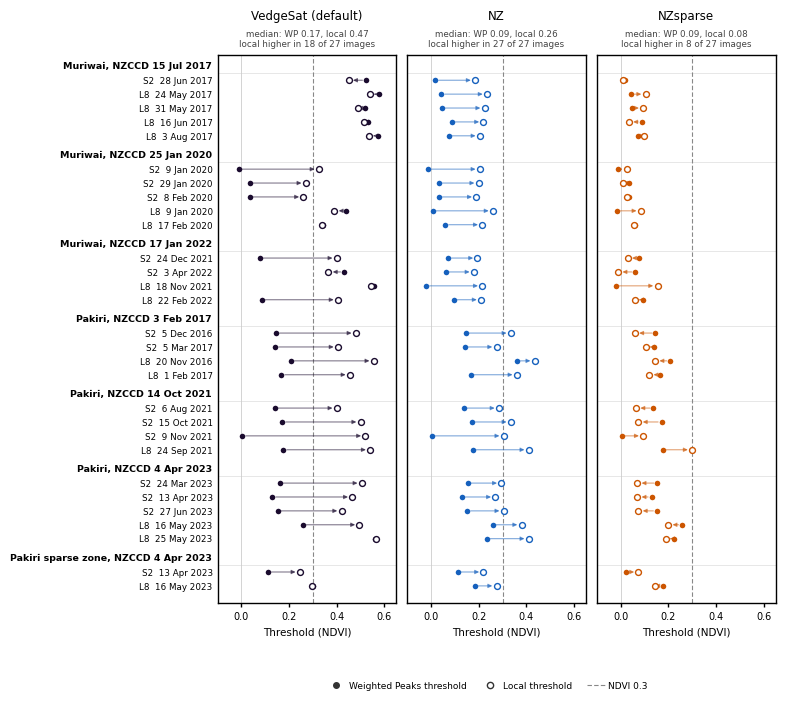

In [2]:
# =====================================================================================
# Weighted Peaks vs local threshold, per image (results, threshold behaviour)
# =====================================================================================
# Reads Data/Extra_analyses/Threshold/thresholds_WP_vs_local_all.csv (from the WP-vs-local threshold cell).
# One row per image, one panel per classifier, same row order as the WP sensitivity strip plot plus the Pakiri
# sparse zone: filled circle = Weighted Peaks threshold, open circle = local threshold, arrow = the change.
# Saves PNG and PDF to Data/Extra_analyses/Threshold (overwritten each run).
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

DATA = os.path.join(os.getcwd(), 'Data')                     # run from the COASTGUARD-master folder
OUT_TH = os.path.join(DATA, 'Extra_analyses', 'Threshold')
CLASSIFIERS = ['VedgeSat', 'NZ', 'NZsparse']
TITLE = {'VedgeSat': 'VedgeSat (default)', 'NZ': 'NZ', 'NZsparse': 'NZsparse'}
COLOUR = {'VedgeSat': '#1a0b2e', 'NZ': '#1560bd', 'NZsparse': '#cc5500'}  # Weighted Peaks colours of the site figures
SITE_NAME = {'Muriwai': 'Muriwai', 'Pakiri': 'Pakiri', 'PakiriSparse': 'Pakiri sparse zone'}
XLIM = (-0.1, 0.65)            # NDVI
HIGH = 0.3                     # dashed reference line, as in the strip plot
ROW_H = 0.16                   # inches per image row

T = pd.read_csv(os.path.join(OUT_TH, 'thresholds_WP_vs_local_all.csv'))
T['date'] = T['date'].astype(str).str[:10]; T['nzccd'] = T['nzccd'].astype(str).str[:10]
W = (T.pivot_table(index=['site', 'nzccd', 'sat', 'date', 'classifier'], columns='method', values='threshold')
       .reset_index())

# row order: site (sparse zone last), NZCCD line, satellite, date
rows = (W[['site', 'nzccd', 'sat', 'date']].drop_duplicates()
        .assign(site_o=lambda d: d.site.map({'Muriwai': 0, 'Pakiri': 1, 'PakiriSparse': 2}),
                sat_o=lambda d: d.sat.map({'S2': 0, 'L8': 1}))
        .sort_values(['site_o', 'nzccd', 'sat_o', 'date']).reset_index(drop=True))
ypos, y, labels, heads = {}, 0, [], []
for (site, nz), g in rows.groupby(['site', 'nzccd'], sort=False):
    heads.append((y, f"{SITE_NAME[site]}, NZCCD {pd.to_datetime(nz).day} {pd.to_datetime(nz):%b %Y}"))
    y += 1
    for r in g.itertuples():
        ypos[(site, nz, r.sat, r.date)] = y
        d = pd.to_datetime(r.date)
        labels.append((y, f"{r.sat}  {d.day} {d:%b %Y}"))
        y += 1
    y += 0.4
n_rows = y

fig, axes = plt.subplots(1, len(CLASSIFIERS), figsize=(7.2, n_rows * ROW_H + 0.9), sharey=True,
                         gridspec_kw=dict(wspace=0.06))
for ax, clf in zip(axes, CLASSIFIERS):
    w = W[W.classifier == clf]
    c = COLOUR[clf]
    for r in w.itertuples():
        yy = ypos[(r.site, r.nzccd, r.sat, r.date)]
        x0, x1 = np.clip(r.WP, *XLIM), np.clip(r.local, *XLIM)
        if abs(x1 - x0) > 0.012:
            ax.annotate('', xy=(x1, yy), xytext=(x0, yy), zorder=2,
                        arrowprops=dict(arrowstyle='-|>', color=c, lw=0.8, alpha=0.55, mutation_scale=6,
                                        shrinkA=2.5, shrinkB=3))
        ax.scatter([x0], [yy], s=16, color=c, lw=0, zorder=3)
        ax.scatter([x1], [yy], s=18, facecolor='white', edgecolor=c, lw=1.0, zorder=4)
    ax.axvline(HIGH, color='#888888', lw=0.8, ls=(0, (4, 2)), zorder=1)
    ax.axvline(0, color='#cccccc', lw=0.6, zorder=1)
    ax.set_xlim(*XLIM)
    main = w[w.site != 'PakiriSparse']
    d = main['local'] - main['WP']
    ax.set_title(f'{TITLE[clf]}\n\n', fontsize=8.5, pad=4)
    ax.text(0.5, 1.012, f'median: WP {main.WP.median():.2f}, local {main["local"].median():.2f}\n'
            f'local higher in {int((d > 0).sum())} of {len(d)} images',
            transform=ax.transAxes, fontsize=6.3, ha='center', va='bottom', color='#444')
    ax.tick_params(axis='x', labelsize=7, length=3, width=1.0)
    ax.tick_params(axis='y', length=0)
    for sp in ax.spines.values():
        sp.set_linewidth(1.0)
    ax.set_xlabel('Threshold (NDVI)', fontsize=7.5)
axes[0].set_yticks([p for p, _ in labels]); axes[0].set_yticklabels([t for _, t in labels], fontsize=6.3)
for p, t in heads:
    axes[0].annotate(t, xy=(0, p), xycoords=('axes fraction', 'data'), xytext=(-4, 0), textcoords='offset points',
                     ha='right', va='center', fontsize=6.8, fontweight='bold', annotation_clip=False)
axes[0].set_ylim(n_rows - 0.2, -0.8)
for ax in axes:
    for p, _ in heads:
        ax.axhline(p + 0.5, color='#dddddd', lw=0.5, zorder=0.5)
fig.legend([Line2D([], [], ls='none', marker='o', ms=4, color='#333333'),
            Line2D([], [], ls='none', marker='o', ms=4.5, mfc='white', mec='#333333'),
            Line2D([], [], color='#888888', lw=0.8, ls=(0, (4, 2)))],
           ['Weighted Peaks threshold', 'Local threshold', f'NDVI {HIGH}'],
           loc='lower center', ncol=3, fontsize=6.5, frameon=False, bbox_to_anchor=(0.5, -0.025),
           handletextpad=0.4, columnspacing=1.6)
os.makedirs(OUT_TH, exist_ok=True)
png = os.path.join(OUT_TH, 'threshold_WP_vs_local.png')
fig.savefig(png, dpi=300, bbox_inches='tight')
fig.savefig(png.replace('.png', '.pdf'), bbox_inches='tight')
print('Saved', png, '(and .pdf)')
display(fig)
plt.close(fig)

In [4]:
# =====================================================================================
# Threshold sensitivity, part 1 of 2: edge accuracy at fixed NDVI thresholds, per image (as Nugraha et al. 2026, Fig. 15)
# =====================================================================================
# For each of the 27 validation images (plus the two Pakiri sparse-zone images) the vegetation edge is redrawn from the
# image's saved NDVI GeoTIFF at a range of fixed thresholds, the same way VedgeSat draws it (NDVI contour inside the
# 200 m reference-line buffer, contours under 500 m dropped), and scored against the NZCCD transects already saved by
# the comparison cells (median of crossings per transect, + = seaward). The classifier only sets the threshold, so each
# image has one accuracy curve and every scenario is a point on it. The scenarios' own thresholds are scored the same
# way and checked against the official errors, so you can see the redraw reproduces the real results.
# Slow part (a few minutes); results are cached, so rerunning only adds missing images. Plots are in part 2.
# Outputs (Data/Extra_analyses/Threshold/Sensitivity):
#   sensitivity_per_image.csv   one row per image x threshold (kind = 'fixed') or per image x scenario (kind = scenario)
#   reproduction_check.csv      redrawn vs official accuracy for every scenario and image
#   best_fixed_threshold.csv    per image: lowest-RMSE fixed threshold vs the six scenarios
import os, glob, numpy as np, pandas as pd, geopandas as gpd, rasterio
from rasterio import features
from skimage import measure
from shapely.geometry import LineString

# ---------------- EDIT ME ----------------
DATA = os.path.join(os.getcwd(), 'Data')                     # run from the COASTGUARD-master folder
TAG = 'BatchS'
THRESHOLDS = np.round(np.arange(-0.10, 0.6001, 0.025), 3)   # NDVI thresholds tested
MAX_DIST_REF = 200      # m, reference-line buffer used in the runs
MIN_LENGTH = 500        # m, contours shorter than this are dropped (min_length_sl in the runs)
RECOMPUTE = False       # True = redo every image (otherwise only images missing from the cache)
# ------------------------------------------
REFLINES = {'Muriwai': 'Muriwai_refLine.shp', 'Pakiri': 'PakiriMain_refLine.shp',
            'PakiriSparse': 'PakiriSparse_refLine.shp'}
TR_DIR = {'Muriwai': os.path.join(DATA, 'NZCCD_comparison_batch'), 'Pakiri': os.path.join(DATA, 'NZCCD_comparison_batch'),
          'PakiriSparse': os.path.join(DATA, 'Extra_analyses', 'NZCCD_comparison_PakiriSparse')}
RUN_LABEL = {('VedgeSat', 'WP'): 'Default (WP)', ('VedgeSat', 'local'): 'Default (local)',
             ('NZ', 'WP'): 'NZ (WP)', ('NZ', 'local'): 'NZ (local)',
             ('NZsparse', 'WP'): 'NZsparse (WP)', ('NZsparse', 'local'): 'NZsparse (local)'}
CRS = 'EPSG:2193'
OUT = os.path.join(DATA, 'Extra_analyses', 'Threshold', 'Sensitivity')
os.makedirs(OUT, exist_ok=True)
CACHE = os.path.join(OUT, 'sensitivity_per_image.csv')


def chunks(geom, n=50):                                      # as in the comparison cells
    out = []
    for p in getattr(geom, 'geoms', [geom]):
        if p.geom_type != 'LineString':
            continue
        c = np.asarray(p.coords)
        for i in range(0, len(c) - 1, n):
            if len(c[i:i + n + 1]) >= 2:
                out.append(LineString(c[i:i + n + 1]))
    return out


def crossings(lines, T):
    """Signed crossing distances (m, + seaward) of all edge pieces on each transect -> median per transect."""
    ch = [c for g in lines for c in chunks(g)]
    if not ch:
        return {}
    tree = gpd.GeoSeries(ch).sindex
    out = {}
    for tid, tr, px, py, nx, ny in zip(T.TransectID, T.geometry, T.px, T.py, T.nx, T.ny):
        pts = []
        for j in tree.query(tr, predicate='intersects'):
            x = tr.intersection(ch[j])
            pts += [g for g in getattr(x, 'geoms', [x]) if g.geom_type == 'Point']
        if pts:
            out[int(tid)] = float(np.median([(q.x - px) * nx + (q.y - py) * ny for q in pts]))
    return out


def edge_lines(im_buf, transform, crs, t):
    """VedgeSat's edge at threshold t: NDVI contour in the buffer, NaN points removed (process_contours),
    pixel -> world as Toolbox.convert_pix2world, contours <= MIN_LENGTH dropped (ProcessShoreline)."""
    lines = []
    for c in measure.find_contours(im_buf, t):
        c = c[~np.isnan(c).any(axis=1)]
        if len(c) < 2:
            continue
        r, k = c[:, 0], c[:, 1]
        x = transform.c + k * transform.a + r * transform.b
        y = transform.f + k * transform.d + r * transform.e
        lines.append(LineString(np.column_stack([x, y])))
    if not lines:
        return []
    g = gpd.GeoSeries(lines, crs=crs)
    g = g[g.length > MIN_LENGTH]
    return list(g.to_crs(CRS)) if len(g) else []


def score(d, n_tr):
    e = np.array(list(d.values()))
    if not len(e):
        return {'n': 0, 'coverage_%': 0.0, 'median_bias_m': np.nan, 'MedAE_m': np.nan, 'RMSE_m': np.nan}
    return {'n': len(e), 'coverage_%': 100 * len(e) / n_tr, 'median_bias_m': np.median(e),
            'MedAE_m': np.median(np.abs(e)), 'RMSE_m': np.sqrt(np.mean(e ** 2))}


def find_ndvi(site, nzccd, filename):
    base = str(filename).split('/')[-1]
    hits = sorted(glob.glob(os.path.join(DATA, f'{TAG}_{site}_{nzccd}_*', 'img_files', f'{base}_NDVI.tif')))
    return hits[0] if hits else None


# ---------------- images and the scenarios' thresholds ----------------
TH = pd.read_csv(os.path.join(DATA, 'Extra_analyses', 'Threshold', 'thresholds_WP_vs_local_all.csv'))
TH['date'] = TH['date'].astype(str).str[:10]; TH['nzccd'] = TH['nzccd'].astype(str).str[:10]
IMGS = TH[['site', 'nzccd', 'sat', 'date', 'filename']].drop_duplicates().reset_index(drop=True)

done = pd.read_csv(CACHE) if (os.path.isfile(CACHE) and not RECOMPUTE) else pd.DataFrame()
if len(done):
    done['date'] = done['date'].astype(str).str[:10]; done['nzccd'] = done['nzccd'].astype(str).str[:10]
have = set(map(tuple, done[['site', 'nzccd', 'sat', 'date']].drop_duplicates().values)) if len(done) else set()

rows, refs, trs = [], {}, {}
for i, im in IMGS.iterrows():
    key = (im.site, im.nzccd, im.sat, im.date)
    if key in have:
        continue
    f = find_ndvi(im.site, im.nzccd, im.filename)
    if f is None:
        print(f'  no NDVI GeoTIFF for {key} ({im.filename}); skipped')
        continue
    print(f'[{i + 1}/{len(IMGS)}] {im.site} {im.sat} {im.date} (NZCCD {im.nzccd})', flush=True)
    with rasterio.open(f) as src:
        nd = src.read(1).astype(float)
        if src.nodata is not None and not np.isnan(src.nodata):
            nd[nd == src.nodata] = np.nan
        transform, crs = src.transform, src.crs
    if (im.site, str(crs)) not in refs:
        ref = gpd.read_file(os.path.join(DATA, 'referenceLines', REFLINES[im.site])).to_crs(crs)
        refs[(im.site, str(crs))] = ref.buffer(MAX_DIST_REF).unary_union
    buf = features.rasterize([(refs[(im.site, str(crs))], 1)], out_shape=nd.shape, transform=transform,
                             fill=0).astype(bool)
    im_buf = nd.copy(); im_buf[~buf] = np.nan
    if (im.site, im.nzccd) not in trs:
        trs[(im.site, im.nzccd)] = gpd.read_file(os.path.join(TR_DIR[im.site],
                                                              f'transects_{im.site}_{im.nzccd}.shp')).to_crs(CRS)
    T = trs[(im.site, im.nzccd)]
    base = {'site': im.site, 'nzccd': im.nzccd, 'sat': im.sat, 'date': im.date}
    for t in THRESHOLDS:
        rows.append({**base, 'kind': 'fixed', 'threshold': float(t),
                     **score(crossings(edge_lines(im_buf, transform, crs, t), T), len(T))})
    sc = TH[(TH.site == im.site) & (TH.nzccd == im.nzccd) & (TH.sat == im.sat) & (TH.date == im.date)]
    for r in sc.itertuples():
        rows.append({**base, 'kind': RUN_LABEL[(r.classifier, r.method)], 'threshold': float(r.threshold),
                     **score(crossings(edge_lines(im_buf, transform, crs, r.threshold), T), len(T))})
    # save as we go, so an interrupted run keeps what it has done
    pd.concat([done, pd.DataFrame(rows)], ignore_index=True).to_csv(CACHE, index=False)

S = pd.read_csv(CACHE)
S['date'] = S['date'].astype(str).str[:10]; S['nzccd'] = S['nzccd'].astype(str).str[:10]

# ---------------- reproduction check: redrawn scenario edges vs the official errors ----------------
OFF = []
for f in [os.path.join(DATA, 'NZCCD_comparison_batch', 'errors_all.csv'),
          os.path.join(DATA, 'Extra_analyses', 'NZCCD_comparison_PakiriSparse', 'errors_all.csv')]:
    if os.path.isfile(f):
        OFF.append(pd.read_csv(f))
OFF = pd.concat(OFF, ignore_index=True)
OFF['date'] = OFF['date'].astype(str).str[:10]; OFF['nzccd_date'] = OFF['nzccd_date'].astype(str).str[:10]
O = (OFF.groupby(['site', 'nzccd_date', 'satname', 'date', 'run'])
        .error_m.agg(n_official='size', RMSE_official=lambda e: np.sqrt(np.mean(e ** 2)),
                     MedAE_official=lambda e: np.median(np.abs(e)))
        .reset_index().rename(columns={'nzccd_date': 'nzccd', 'satname': 'sat', 'run': 'kind'}))
C = S[S.kind != 'fixed'].merge(O, on=['site', 'nzccd', 'sat', 'date', 'kind'], how='left')
C['RMSE_diff'] = (C.RMSE_m - C.RMSE_official).round(2)
C['n_diff'] = C.n - C.n_official
C.to_csv(os.path.join(OUT, 'reproduction_check.csv'), index=False)
ok = C.RMSE_diff.abs() <= 1
print(f'\nReproduction check: redrawn RMSE within 1 m of the official RMSE for {int(ok.sum())} of {len(C)} '
      f'scenario x image edges (median |difference| {C.RMSE_diff.abs().median():.2f} m; '
      f'transects scored differ by a median of {C.n_diff.abs().median():.0f}).')
if (~ok).any():
    print('Largest differences:')
    print(C.loc[~ok].reindex(C.loc[~ok].RMSE_diff.abs().sort_values(ascending=False).index)
          [['site', 'sat', 'date', 'kind', 'threshold', 'n', 'n_official', 'RMSE_m', 'RMSE_official']]
          .head(12).round(2).to_string(index=False))

# ---------------- best fixed threshold per image ----------------
MIN_COV = 50          # %: a fixed threshold only counts if its edge crosses at least this share of transects
F = S[(S.kind == 'fixed') & (S['coverage_%'] >= MIN_COV)]
best = F.loc[F.groupby(['site', 'nzccd', 'sat', 'date']).RMSE_m.idxmin(),
             ['site', 'nzccd', 'sat', 'date', 'threshold', 'RMSE_m', 'coverage_%']]
best = best.rename(columns={'threshold': 'best_threshold', 'RMSE_m': 'best_RMSE_m', 'coverage_%': 'best_coverage_%'})
scen = S[S.kind != 'fixed'].pivot_table(index=['site', 'nzccd', 'sat', 'date'], columns='kind', values='RMSE_m')
best = best.merge(scen.reset_index(), on=['site', 'nzccd', 'sat', 'date'], how='left').round(2)
best.to_csv(os.path.join(OUT, 'best_fixed_threshold.csv'), index=False)
with pd.option_context('display.width', 250, 'display.max_columns', 20):
    print('\nLowest-RMSE fixed threshold per image (coverage >= 50%), with each scenario\'s RMSE:')
    print(best.to_string(index=False))
print('\nSaved to', OUT)

[1/29] Muriwai S2 2017-06-28 (NZCCD 2017-07-15)


/var/folders/py/mqkq5vqn2mld4qxmg47bc80c0000gp/T/ipykernel_53539/1441909461.py:130: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  refs[(im.site, str(crs))] = ref.buffer(MAX_DIST_REF).unary_union


[2/29] Muriwai L8 2017-05-24 (NZCCD 2017-07-15)
[3/29] Muriwai L8 2017-06-16 (NZCCD 2017-07-15)
[4/29] Muriwai L8 2017-08-03 (NZCCD 2017-07-15)
[5/29] Muriwai L8 2017-05-31 (NZCCD 2017-07-15)
[6/29] Muriwai S2 2020-01-09 (NZCCD 2020-01-25)
[7/29] Muriwai S2 2020-01-29 (NZCCD 2020-01-25)
[8/29] Muriwai S2 2020-02-08 (NZCCD 2020-01-25)
[9/29] Muriwai L8 2020-01-09 (NZCCD 2020-01-25)
[10/29] Muriwai L8 2020-02-17 (NZCCD 2020-01-25)
[11/29] Muriwai S2 2021-12-24 (NZCCD 2022-01-17)
[12/29] Muriwai S2 2022-04-03 (NZCCD 2022-01-17)
[13/29] Muriwai L8 2022-02-22 (NZCCD 2022-01-17)
[14/29] Muriwai L8 2021-11-18 (NZCCD 2022-01-17)
[15/29] PakiriSparse S2 2023-04-13 (NZCCD 2023-04-04)


/var/folders/py/mqkq5vqn2mld4qxmg47bc80c0000gp/T/ipykernel_53539/1441909461.py:130: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  refs[(im.site, str(crs))] = ref.buffer(MAX_DIST_REF).unary_union


[16/29] PakiriSparse L8 2023-05-16 (NZCCD 2023-04-04)
[17/29] Pakiri S2 2016-12-05 (NZCCD 2017-02-03)


/var/folders/py/mqkq5vqn2mld4qxmg47bc80c0000gp/T/ipykernel_53539/1441909461.py:130: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  refs[(im.site, str(crs))] = ref.buffer(MAX_DIST_REF).unary_union


[18/29] Pakiri S2 2017-03-05 (NZCCD 2017-02-03)
[19/29] Pakiri L8 2017-02-01 (NZCCD 2017-02-03)
[20/29] Pakiri L8 2016-11-20 (NZCCD 2017-02-03)
[21/29] Pakiri S2 2021-08-06 (NZCCD 2021-10-14)
[22/29] Pakiri S2 2021-10-15 (NZCCD 2021-10-14)
[23/29] Pakiri S2 2021-11-09 (NZCCD 2021-10-14)
[24/29] Pakiri L8 2021-09-24 (NZCCD 2021-10-14)
[25/29] Pakiri S2 2023-03-24 (NZCCD 2023-04-04)
[26/29] Pakiri S2 2023-04-13 (NZCCD 2023-04-04)
[27/29] Pakiri S2 2023-06-27 (NZCCD 2023-04-04)
[28/29] Pakiri L8 2023-05-25 (NZCCD 2023-04-04)
[29/29] Pakiri L8 2023-05-16 (NZCCD 2023-04-04)

Reproduction check: redrawn RMSE within 1 m of the official RMSE for 169 of 174 scenario x image edges (median |difference| 0.00 m; transects scored differ by a median of 0).
Largest differences:
   site sat       date            kind  threshold   n  n_official  RMSE_m  RMSE_official
Muriwai  S2 2020-01-09 Default (local)       0.33 399         399   34.69          37.52
Muriwai  L8 2017-06-16    Default (WP)       0.53

Saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Extra_analyses/Threshold/Sensitivity/threshold_sensitivity_pairs.png (and .pdf)


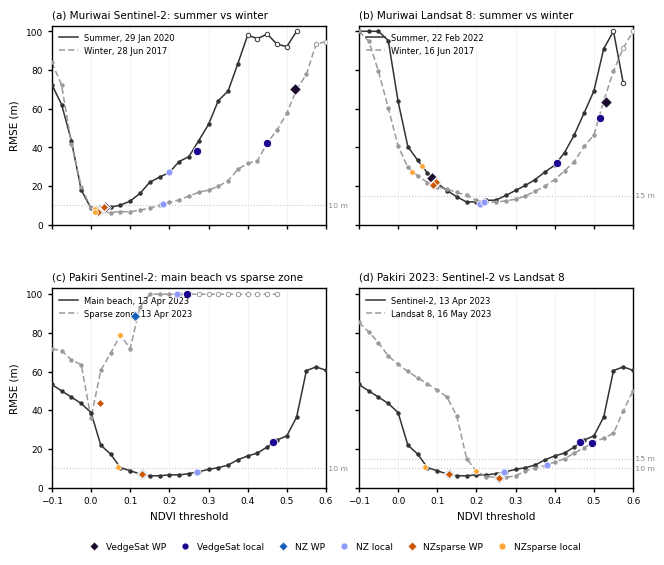

Saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Extra_analyses/Threshold/Sensitivity/threshold_sensitivity_all_images.png (and .pdf)


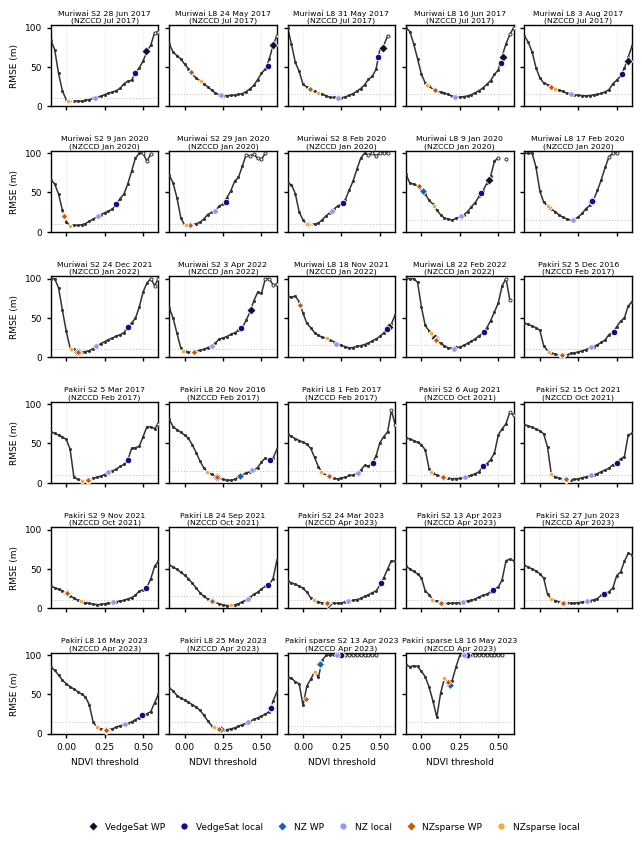

In [5]:
# =====================================================================================
# Threshold sensitivity, part 2 of 2: plots (run part 1 first; this part is quick, rerun it to change the plots)
# =====================================================================================
# Figure 1 (as Nugraha et al. 2026, Fig. 15): four panels, each comparing two images. Line = edge accuracy at fixed NDVI
#   thresholds; markers = the six scenarios at their own thresholds. Hollow line points: the edge crossed fewer than
#   MIN_COV % of transects at that threshold (accuracy from few transects). Values above YMAX are drawn on the top axis.
# Figure 2 (appendix): the same for every image, one small panel each. Dotted line = one pixel (10 m S2, 15 m L8).
# Default, NZ and NZsparse WP often share a threshold: their markers are nested (largest = VedgeSat).
# Saves PNG and PDF to Data/Extra_analyses/Threshold/Sensitivity (overwritten each run).
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

DATA = os.path.join(os.getcwd(), 'Data')
OUT = os.path.join(DATA, 'Extra_analyses', 'Threshold', 'Sensitivity')

# ---------------- EDIT ME ----------------
METRIC = 'RMSE_m'       # or 'MedAE_m'
YMAX = 100              # m, top of the y axis
MIN_COV = 50            # %, line points with lower transect coverage are drawn hollow
XLIM = (-0.1, 0.6)
# (title, [(site, NZCCD date, satellite, image date, legend label), (...)])
PAIRS = [
    ('Muriwai Sentinel-2: summer vs winter',
     [('Muriwai', '2020-01-25', 'S2', '2020-01-29', 'Summer, 29 Jan 2020'),
      ('Muriwai', '2017-07-15', 'S2', '2017-06-28', 'Winter, 28 Jun 2017')]),
    ('Muriwai Landsat 8: summer vs winter',
     [('Muriwai', '2022-01-17', 'L8', '2022-02-22', 'Summer, 22 Feb 2022'),
      ('Muriwai', '2017-07-15', 'L8', '2017-06-16', 'Winter, 16 Jun 2017')]),
    ('Pakiri Sentinel-2: main beach vs sparse zone',
     [('Pakiri', '2023-04-04', 'S2', '2023-04-13', 'Main beach, 13 Apr 2023'),
      ('PakiriSparse', '2023-04-04', 'S2', '2023-04-13', 'Sparse zone, 13 Apr 2023')]),
    ('Pakiri 2023: Sentinel-2 vs Landsat 8',
     [('Pakiri', '2023-04-04', 'S2', '2023-04-13', 'Sentinel-2, 13 Apr 2023'),
      ('Pakiri', '2023-04-04', 'L8', '2023-05-16', 'Landsat 8, 16 May 2023')]),
]
# ------------------------------------------
SCEN = ['Default (WP)', 'Default (local)', 'NZ (WP)', 'NZ (local)', 'NZsparse (WP)', 'NZsparse (local)']
SCEN_NAME = {'Default (WP)': 'VedgeSat WP', 'Default (local)': 'VedgeSat local', 'NZ (WP)': 'NZ WP',
             'NZ (local)': 'NZ local', 'NZsparse (WP)': 'NZsparse WP', 'NZsparse (local)': 'NZsparse local'}
SCEN_COLOUR = {'Default (WP)': '#1a0b2e', 'Default (local)': '#1b068d', 'NZ (WP)': '#1560bd',
               'NZ (local)': '#8f99fb', 'NZsparse (WP)': '#cc5500', 'NZsparse (local)': '#fca636'}  # site figures
SCEN_MARKER = {k: ('D' if 'WP' in k else 'o') for k in SCEN}
# default and NZ (and often NZsparse) share a WP threshold, so their markers are nested by size to stay visible
SCEN_SIZE = {k: {'Default': 1.35, 'NZ': 1.0, 'NZsparse': 0.65}[k.split(' (')[0]] for k in SCEN}
IMG_STYLE = [dict(color='#333333', ls='-'), dict(color='#9a9a9a', ls=(0, (4, 2)))]
PIXEL = {'S2': 10, 'L8': 15}
SITE_NAME = {'Muriwai': 'Muriwai', 'Pakiri': 'Pakiri', 'PakiriSparse': 'Pakiri sparse'}
YLAB = {'RMSE_m': 'RMSE (m)', 'MedAE_m': 'MedAE (m)'}[METRIC]

S = pd.read_csv(os.path.join(OUT, 'sensitivity_per_image.csv'))
S['date'] = S['date'].astype(str).str[:10]; S['nzccd'] = S['nzccd'].astype(str).str[:10]


def draw(ax, key, style, label=None, ms=3.2, mks=26):
    site, nz, sat, date = key
    s = S[(S.site == site) & (S.nzccd == nz) & (S.sat == sat) & (S.date == date)]
    if not len(s):
        print('no results for', key); return False
    f = s[s.kind == 'fixed'].sort_values('threshold')
    y = f[METRIC].clip(upper=YMAX)
    ax.plot(f.threshold, y, lw=1.1, zorder=2, label=label, **style)
    good = f['coverage_%'] >= MIN_COV
    ax.scatter(f.threshold[good], y[good], s=ms ** 2, color=style['color'], zorder=3, lw=0)
    ax.scatter(f.threshold[~good], y[~good], s=ms ** 2, facecolor='white', edgecolor=style['color'], lw=0.7, zorder=3)
    for r in s[s.kind != 'fixed'].itertuples():
        v = getattr(r, METRIC)
        if np.isnan(v):
            continue
        ax.scatter([r.threshold], [min(v, YMAX)], s=mks * SCEN_SIZE[r.kind], marker=SCEN_MARKER[r.kind],
                   color=SCEN_COLOUR[r.kind], edgecolor='white', lw=0.6, zorder=5 + {'Default': 0, 'NZ': 1, 'NZsparse': 2}[r.kind.split(' (')[0]])
    return True


def frame(ax, sats, label=True):
    for sat in sorted(set(sats)):
        ax.axhline(PIXEL[sat], color='#bbbbbb', lw=0.7, ls=(0, (1, 2)), zorder=1)
        if label: ax.text(XLIM[1], PIXEL[sat], f' {PIXEL[sat]} m', fontsize=5.5, color='#888888', va='center', ha='left')
    ax.set_xlim(*XLIM); ax.set_ylim(0, YMAX * 1.03)
    ax.grid(axis='x', color='#eeeeee', lw=0.5, zorder=0)
    for sp in ax.spines.values():
        sp.set_linewidth(1.0)
    ax.tick_params(labelsize=6.5, length=3, width=1.0)


scen_handles = [Line2D([], [], ls='none', marker=SCEN_MARKER[k], ms=5.5, mfc=SCEN_COLOUR[k], mec='white')
                for k in SCEN]

# ---------------- Figure 1: pairs ----------------
fig, axes = plt.subplots(2, 2, figsize=(7.5, 6.0), sharex=True, sharey=True,
                         gridspec_kw=dict(hspace=0.32, wspace=0.12))
for ax, (title, imgs), letter in zip(axes.flat, PAIRS, 'abcd'):
    for (site, nz, sat, date, lab), st in zip(imgs, IMG_STYLE):
        draw(ax, (site, nz, sat, date), st, label=lab)
    frame(ax, [i[2] for i in imgs])
    ax.set_title(f'({letter}) {title}', fontsize=7.5, loc='left')
    ax.legend(fontsize=6, frameon=False, loc='upper left', handlelength=2.2)
for ax in axes[1]:
    ax.set_xlabel('NDVI threshold', fontsize=7.5)
for ax in axes[:, 0]:
    ax.set_ylabel(YLAB, fontsize=7.5)
fig.legend(scen_handles, [SCEN_NAME[k] for k in SCEN], loc='lower center', ncol=6, fontsize=6.5, frameon=False,
           bbox_to_anchor=(0.5, -0.01), handletextpad=0.3, columnspacing=1.1)
fig.subplots_adjust(bottom=0.11)
png = os.path.join(OUT, 'threshold_sensitivity_pairs.png')
fig.savefig(png, dpi=300, bbox_inches='tight'); fig.savefig(png.replace('.png', '.pdf'), bbox_inches='tight')
print('Saved', png, '(and .pdf)')
display(fig); plt.close(fig)

# ---------------- Figure 2: every image ----------------
imgs = (S[['site', 'nzccd', 'sat', 'date']].drop_duplicates()
        .assign(o1=lambda d: d.site.map({'Muriwai': 0, 'Pakiri': 1, 'PakiriSparse': 2}),
                o2=lambda d: d.sat.map({'S2': 0, 'L8': 1}))
        .sort_values(['o1', 'nzccd', 'o2', 'date']).reset_index(drop=True))
NC = 5
NR = int(np.ceil(len(imgs) / NC))
fig, axes = plt.subplots(NR, NC, figsize=(7.5, 1.45 * NR + 0.5), sharex=True, sharey=True,
                         gridspec_kw=dict(hspace=0.55, wspace=0.1))
for ax, r in zip(axes.flat, imgs.itertuples()):
    draw(ax, (r.site, r.nzccd, r.sat, r.date), IMG_STYLE[0], ms=2.2, mks=16)
    frame(ax, [r.sat], label=False)
    d, n = pd.to_datetime(r.date), pd.to_datetime(r.nzccd)
    ax.set_title(f'{SITE_NAME[r.site]} {r.sat} {d.day} {d:%b %Y}\n(NZCCD {n:%b %Y})', fontsize=5.6, pad=2)
for ax in axes.flat[len(imgs):]:
    ax.axis('off')
for ax in axes[-1]:
    ax.set_xlabel('NDVI threshold', fontsize=6.5)
for ax in axes[:, 0]:
    ax.set_ylabel(YLAB, fontsize=6.5)
fig.legend(scen_handles, [SCEN_NAME[k] for k in SCEN], loc='lower center', ncol=6, fontsize=6.5, frameon=False,
           bbox_to_anchor=(0.5, -0.005), handletextpad=0.3, columnspacing=1.1)
png = os.path.join(OUT, 'threshold_sensitivity_all_images.png')
fig.savefig(png, dpi=300, bbox_inches='tight'); fig.savefig(png.replace('.png', '.pdf'), bbox_inches='tight')
print('Saved', png, '(and .pdf)')
display(fig); plt.close(fig)